# Imports

In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("cpu")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    set_priors,
    run_fit,
    posthoc_samples,
)
from results import (
    save_run,
    to_idata,
)

from plotting import (
    plot_burst_TD, 
    plot_burst_FD,
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import arviz as az
import arviz_plots as azp
az.rcParams["plot.max_subplots"] = 200

import random

FRBayes: running on the CPU with 8 cores (up to 8 chains in parallel)


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
cpu
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3), CpuDevice(id=4), CpuDevice(id=5), CpuDevice(id=6), CpuDevice(id=7)]
local device count: 8


# Setup

In [2]:
from pathlib import Path

PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 3 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=8,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "22154974_BB" # Single-pulse, Broadband with scatter
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

820 good channels -> 51 blocks of 16 (4 dropped); block span median 6.641 MHz, max 36.719 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 19 of 165 bins (up to 5.6 kHz of 48.7 kHz)
weighted mean frequency 458.5 MHz, reference frequency 451.7 MHz


In [3]:
burst.data_fd.shape

(51, 19)

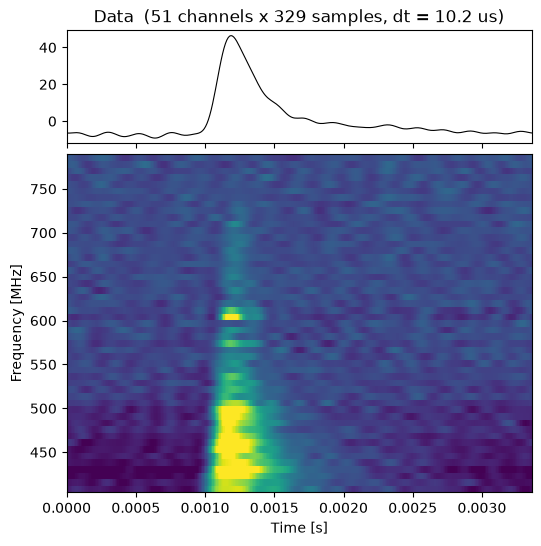

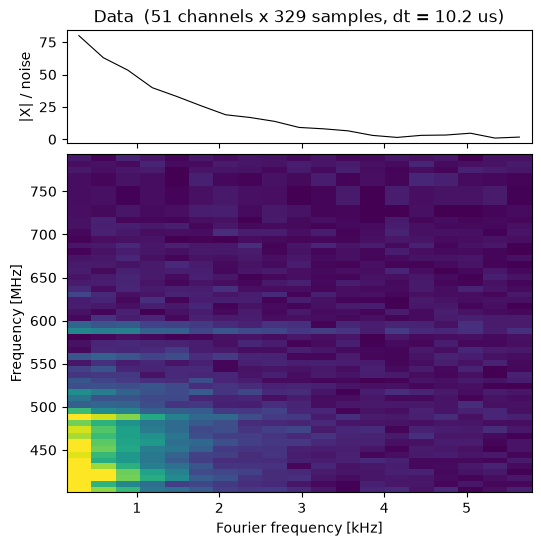

In [4]:
# M_FD = jnp.sum(jax.vmap(single_pulse_fn)(params), axis=0)    # (n_chan, n_fourier)

plot_burst_TD(burst);                                          # data, in time
# plot_burst_TD(burst, M_FD, title="Model")                     # model, in time
plot_burst_FD(burst);                                          # data, in Fourier space
# plot_burst_FD(burst, burst.data_fd - M_FD, title="Residual")  # residual, in Fourier space

# Run

In [5]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

n_pulses = 1
num_chains = 8
target_accept_prob = 0.8
seed = 1
num_warmup = 500
num_samples = 200
progress_bar = True
# repulsion_dict = {"x_min":0.75}
repulsion_dict={}


priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0)
# priors = set_priors(burst, single_pulse_fn, s_opt=100.0, gamma_range=(-10.0, 30.0),beta_range=(-10.0, 30.0))
mcmc = run_fit(burst, single_pulse_fn, priors, FD_gaussianlikelihood, seed=seed,
               num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
               num_warmup=num_warmup, num_samples=num_samples, progress_bar=progress_bar,
               repulsion=repulsion_dict)
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})    
    # idata  = save_run(None, mcmc, burst, priors, data_path,
#                   single_pulse_fn=single_pulse_fn, extra_samples=extra, event_id=event_id)

prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010794160025647014
prior being set with bounds:
c1_min = -4.423541 
c1_max = 20.592485 
c2_min = -3.457661 
c2_max = 0.17288305
mean_arrival_time: Uniform(low=0, high=0.00335872)
DM: Uniform(low=-0.0898636, high=0.0898636)
sigma: Uniform(low=2.82203e-05, high=0.000561493)
tau_ref: Uniform(low=0, high=0.00107942)
c1: Uniform(low=-4.42354, high=20.5925)
c2: Uniform(low=-3.45766, high=0.172883)
A_snr: HalfNormal(scale=100)
run_fit seed: 1
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]

  0%|          | 0/700 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]


  0%|          | 0/700 [00:00<?, ?it/s]


Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]



  0%|          | 0/700 [00:00<?, ?it/s]



Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]




  0%|          | 0/700 [00:00<?, ?it/s]




Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]





  0%|          | 0/700 [00:00<?, ?it/s]





Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]






  0%|          | 0/700 [00:00<?, ?it/s]






Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


Running chain 1:   0%|          | 0/700 [00:03<?, ?it/s]

Running chain 2:   0%|          | 0/700 [00:03<?, ?it/s]


Running chain 3:   0%|          | 0/700 [00:03<?, ?it/s]



Running chain 4:   0%|          | 0/700 [00:03<?, ?it/s]




Running chain 5:   0%|          | 0/700 [00:03<?, ?it/s]





Running chain 6:   0%|          | 0/700 [00:03<?, ?it/s]






Running chain 7:   0%|          | 0/700 [00:03<?, ?it/s]

Running chain 2:  10%|█         | 70/700 [00:03<00:01, 537.42it/s]


Running chain 3:  10%|█         | 70/700 [00:03<00:01, 586.53it/s]





Running chain 6:  10%|█         | 70/700 [00:03<00:01, 590.21it/s]



Running chain 4:  10%|█         | 70/700 [00:03<00:01, 327.40it/s]


Running chain 3:  15%|█▌        | 105/700 [00:03<00:01, 451.96it/s]






Running chain 7:  10%|█         | 70/700 [00:03<00:01, 318.11it/s]





Running chain 1:   5%|▌         | 35/700 [00:03<00:05, 123.61it/s]




Running chain 5:   5%|▌         | 35/700 [00:03<00:07, 93.92it/s]






Running ch

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [6]:
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"]).astype(bool)   # (chain, draw)
print("divergences per chain:", div.sum(axis=1))
# s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
# snr_on = 3.0                                                       # whatever you used
# checks = {
#     "closest-pair x":         s["toa_separation"].min(axis=-1),
#     "smallest A_snr":         s["A_snr"].min(axis=-1),
#     "pulse near snr_on (frac)": (np.abs(s["A_snr"] - snr_on) < 1.0).any(axis=-1).astype(float),
# }
# for name, v in checks.items():
#     print(f"{name:25s} divergent: {np.median(v[div]) if 'frac' not in name else v[div].mean():.2f}   "
#           f"others: {np.median(v[~div]) if 'frac' not in name else v[~div].mean():.2f}")

divergences per chain: [0 0 0 0 0 0 0 0]


In [7]:
steps = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])     # (chain, draw), after warmup
depth = np.ceil(np.log2(steps + 1)).astype(int)
max_depth = 10                                                                    # whatever the run used
for c in range(steps.shape[0]):
    print(f"chain {c}: median depth {np.median(depth[c]):.0f}   max {depth[c].max()}   "
          f"hit the limit {np.mean(steps[c] >= 2 ** max_depth - 1):.0%}   mean steps {steps[c].mean():.0f}")

chain 0: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 1: median depth 4   max 5   hit the limit 0%   mean steps 13
chain 2: median depth 4   max 5   hit the limit 0%   mean steps 14
chain 3: median depth 8   max 8   hit the limit 0%   mean steps 174
chain 4: median depth 4   max 5   hit the limit 0%   mean steps 13
chain 5: median depth 4   max 5   hit the limit 0%   mean steps 14
chain 6: median depth 7   max 8   hit the limit 0%   mean steps 140
chain 7: median depth 6   max 7   hit the limit 0%   mean steps 73


In [8]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.001,0.000,0.001,0.001,1098.946,1133.770,1.011,0.000,0.000
A_snr[0],196.351,0.967,194.826,197.861,1350.652,954.725,1.007,0.026,0.026
DM[0],-0.007,0.000,-0.008,-0.007,1517.278,1098.824,1.003,0.000,0.000
DM_shared,-0.007,0.000,-0.008,-0.007,1517.278,1098.824,1.003,0.000,0.000
beta[0],-15.262,0.729,-16.456,-14.097,1131.949,1019.456,1.011,0.022,0.020
c1[0],-0.768,0.011,-0.786,-0.750,1219.102,1162.054,1.004,0.000,0.000
c2[0],-0.264,0.013,-0.284,-0.244,1131.949,1019.456,1.011,0.000,0.000
gamma[0],-4.981,0.067,-5.090,-4.868,1661.599,1329.827,1.002,0.002,0.002
log_sed_peak[0],0.573,0.009,0.559,0.587,1569.218,1311.933,1.004,0.000,0.000
mean_arrival_time[0],0.001,0.000,0.001,0.001,1333.126,1339.821,1.001,0.000,0.000


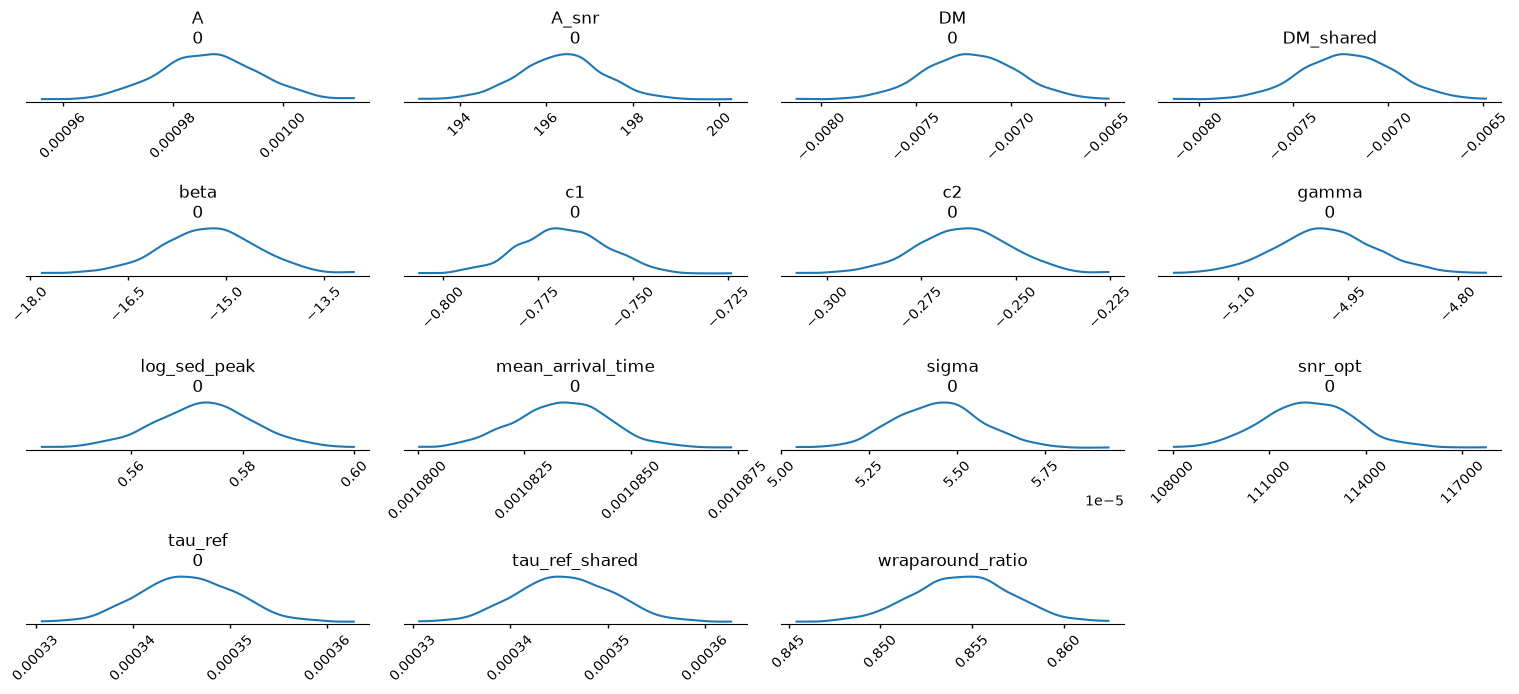

In [9]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

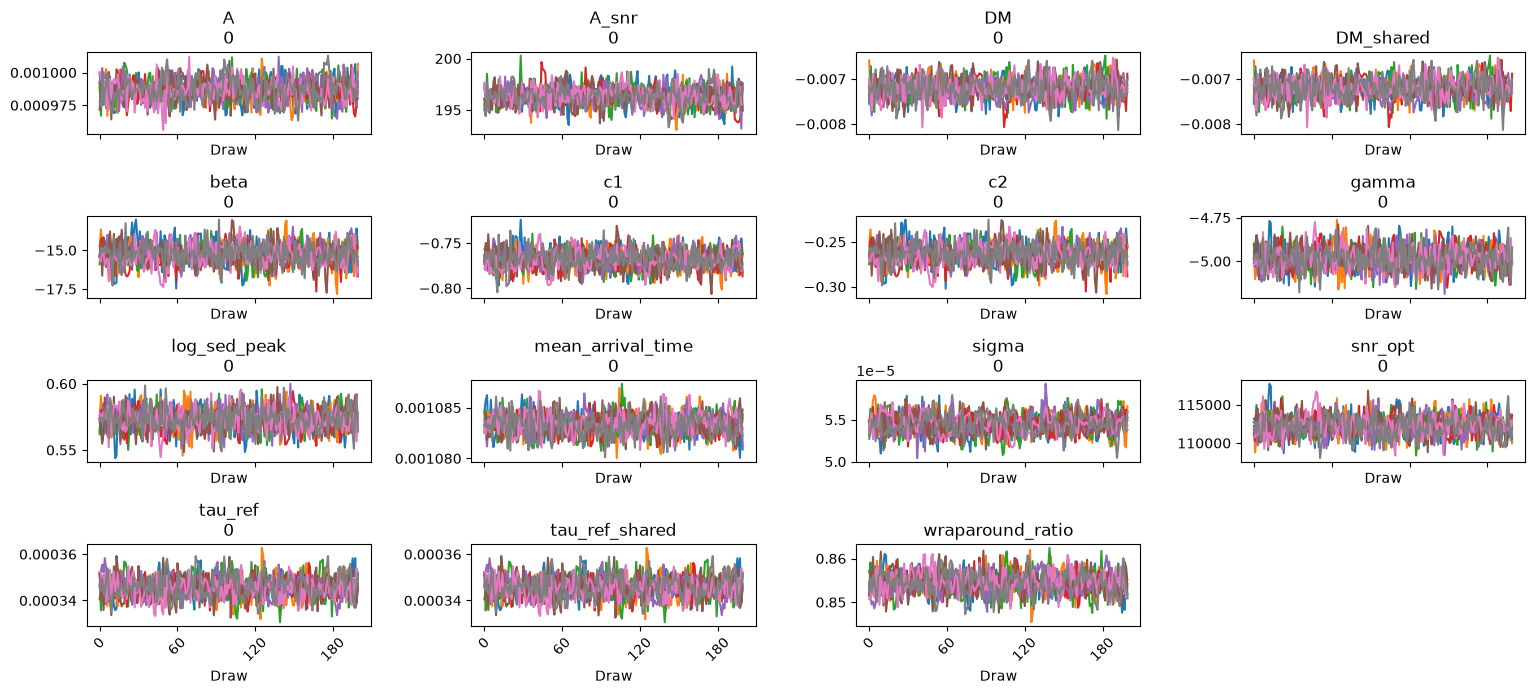

In [10]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="Explicitly requested dtype.*is not available",
    category=UserWarning,
)

azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [11]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in range(pe.shape[0]):
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 0: -log post    2608.4 ±  1.6   active 1.0   t [ms] [1.08]   A_snr [196.5]
chain 1: -log post    2608.5 ±  2.0   active 1.0   t [ms] [1.08]   A_snr [196.3]
chain 2: -log post    2608.3 ±  1.9   active 1.0   t [ms] [1.08]   A_snr [196.3]
chain 3: -log post    2607.8 ±  1.7   active 1.0   t [ms] [1.08]   A_snr [196.3]
chain 4: -log post    2608.3 ±  1.6   active 1.0   t [ms] [1.08]   A_snr [196.4]
chain 5: -log post    2608.3 ±  1.8   active 1.0   t [ms] [1.08]   A_snr [196.4]
chain 6: -log post    2608.2 ±  1.8   active 1.0   t [ms] [1.08]   A_snr [196.4]
chain 7: -log post    2608.5 ±  2.1   active 1.0   t [ms] [1.08]   A_snr [196.4]


In [12]:
key = jax.random.PRNGKey(31)

  from chain 1
Plotting for Posterior Draw #267, 1 pulse(s)
A_snr [196.7757]
sigma [5.5108263e-05]
tau_ref [0.00034305]


/tmp/ipykernel_21452/420995344.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


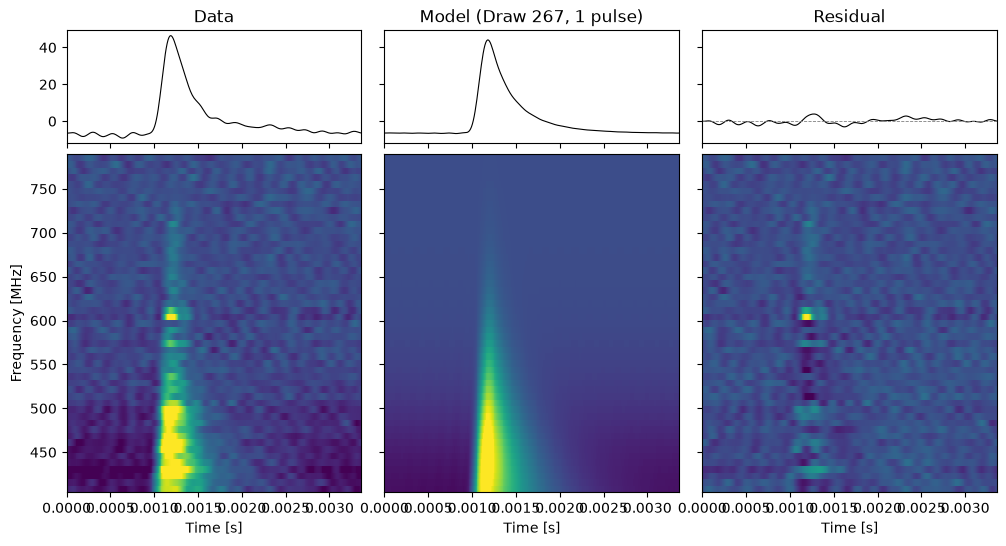

In [13]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# For a marginalized fit, the fluences are not sampled: add the post-hoc draws first, flattened
# to (draws, n_pulses) to match get_samples(), e.g.
#     samples["A"] = extra["A"].reshape(-1, extra["A"].shape[-1])
if "A" not in samples:
    raise KeyError("samples has no 'A'. For a marginalized fit, add the fluences drawn by "
                   "posthoc_samples first (see the comment above).")

num_draws = len(next(iter(samples.values())))
n_pulses = samples["mean_arrival_time"].shape[-1]

# Pick a draw index using JAX random
# key = jax.random.PRNGKey(110)
# key = jax.random.PRNGKey(5)

keep_chains = [1,3]                                        # the chains to draw from
n_per_chain = num_draws // mcmc.num_chains
allowed = np.concatenate([np.arange(c * n_per_chain, (c + 1) * n_per_chain) for c in keep_chains])
draw_idx = int(allowed[jax.random.randint(key, shape=(), minval=0, maxval=len(allowed))])

# Parameters of the chosen draw, each an array of shape (n_pulses,). Only the parameters the
# model reads are taken; 'A' is the fluence, which single_pulse_fn applies itself.
param_names = [k for k in ("mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2",
                           "gamma", "beta", "delta", "A", "A_snr") if k in samples]
test_params = {k: jnp.asarray(samples[k][draw_idx]).reshape(n_pulses) for k in param_names}

print(f"  from chain {draw_idx // n_per_chain}")
print(f"Plotting for Posterior Draw #{draw_idx}, {n_pulses} pulse(s)")
print("A_snr",test_params["A_snr"])
print("sigma",test_params["sigma"])
print("tau_ref",test_params["tau_ref"])

# Evaluate every pulse (vmap over the pulse axis), then sum them for the full model
M_FD_pulses = jax.vmap(single_pulse_fn)(test_params)       # (n_pulses, nfreq, nfourier)
M_FD = jnp.sum(M_FD_pulses, axis=0)                        # (nfreq, nfourier)

# The data and model live on the retained Fourier bins only, so each bin is put back at its own
# index on the full rfft grid before inverting; irfft on the truncated array would reinterpret
# bin k as frequency k / (Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt = burst.dt
n_full = Nseg // 2 + 1
bin_index = jnp.rint(jnp.asarray(burst.fourier_freqs).reshape(-1) * Nseg * dt).astype(int)
pad = lambda X: jnp.zeros(X.shape[:-1] + (n_full,), X.dtype).at[..., bin_index].set(X)

to_TD = lambda X: (1.0 / dt) * jnp.fft.irfft(pad(X), n=Nseg, axis=-1)
M_TD = to_TD(M_FD)
M_TD_pulses = to_TD(M_FD_pulses)                           # (n_pulses, nfreq, ntime)
data_TD = to_TD(burst.data_fd)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
pulse_ts = jnp.nansum(M_TD_pulses, axis=1)                 # (n_pulses, ntime)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8, label="sum")
if n_pulses > 1:
    # Each component separately, and its arrival time (at the reference frequency)
    colors = plt.cm.tab10(np.arange(n_pulses) % 10)
    t0 = np.asarray(test_params["mean_arrival_time"])
    for j in range(n_pulses):
        ax_ts_model.plot(time_plot, pulse_ts[j], color=colors[j], lw=0.8, ls="--", label=f"pulse {j}")
        # for ax in (ax_ts_model, ax_wf_model):
        #     ax.axvline(t0[j], color=colors[j], lw=0.6, alpha=0.6)
    ax_ts_model.legend(fontsize=7, loc="upper right")
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx}, {n_pulses} pulse{'s' if n_pulses > 1 else ''})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 45.13725
Max Model abs: 42.532333
whitened residual sd: 1.643  (expect 1)


/tmp/ipykernel_21452/1018850176.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


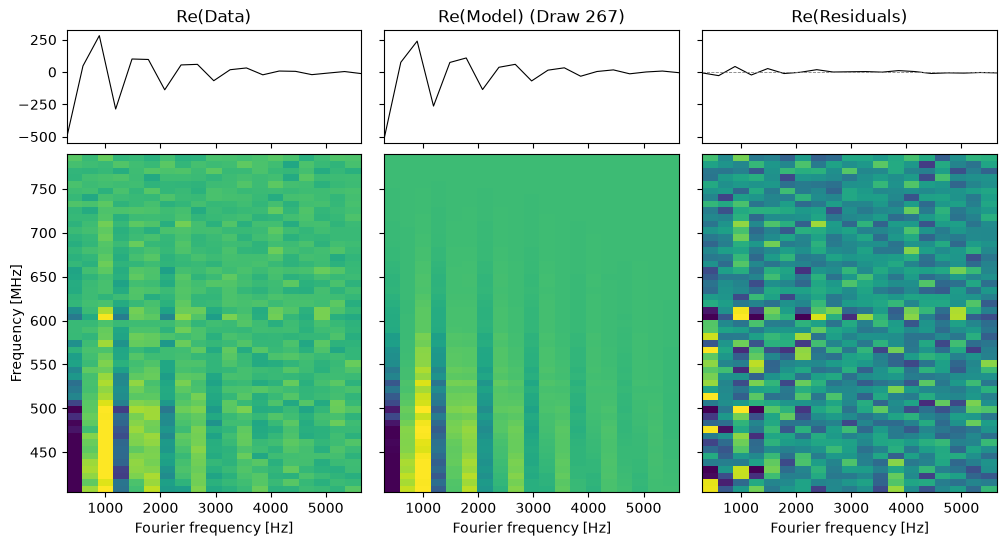

In [14]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
# test_params comes from the posterior-draw cell: each entry has shape (n_pulses,). Every pulse
# is evaluated (vmap over the pulse axis) and the pulses are summed into the full model.
M_FD = jnp.sum(jax.vmap(single_pulse_fn)(test_params), axis=0)     # (nfreq, nfourier)

# The data and the model already live on the truncated Fourier axis, which is exactly the set
# of bins the likelihood uses, so nothing needs slicing here.
data_reshaped_FFT = burst.data_fd
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Re(Model) (Draw {draw_idx})")
ax_ts_data.set_title("Re(Data)")
ax_ts_resid.set_title("Re(Residuals)")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()